# 02. Dataset analysis (Midterm part A)

Needs `data/index.csv` and the extracted audio from `01_data_prep.ipynb`. Runs on CPU. Written up in [`docs/dataset_analysis.md`](../docs/dataset_analysis.md).

*Generated by `scripts/build_notebooks.py` from the `.py` files; edit those and rebuild, not this notebook.*

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/DataSEC-Sound-Classification")  # <- where the repository is on Drive
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
# os.environ["ATI_CONFIG"] = "configs/default.yaml"  # optional: another config (read when src.utils is imported)

import pandas as pd
from IPython.display import Image, display

print("repository:", ROOT)

repository: C:\ATI\DataSEC-Sound-Classification-main


## 1. Class balance, durations, representations, spectral similarity

Source: `scripts/eda.py`

Exploratory data analysis for Midterm part A: writes results/figures/eda_*.png and results/tables/eda_*.csv.

Covers clip counts per macro-class, class balance, duration statistics (+ duration-only shortcut check),
waveform / linear spectrogram / log-Mel of contrasting classes, the Mel filterbank, class-mean log-Mel
spectra and spectral similarity between classes. Needs data/index.csv and the extracted raw audio.

In [2]:
import sys
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
import soxr
import torch
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from src.data import class_weights, crop_or_pad
from src.features import build_logmel
from src.utils import RESULTS, load_classes, load_config, resolve

In [3]:
# contrasting sound types: impulsive / harmonic / broadband / speech
EXAMPLES = {"Gunshot (impulsive)": "Thunder fireworks and gunshot/Gunshot",
            "Sirens (harmonic, tonal)": "Sirens and alarms/Sirens",
            "Jet aircraft (broadband)": "Jet aircrafts",
            "Voices (speech)": "Voices"}

In [4]:
def main_eda() -> None:
    cfg, classes = load_config(), load_classes()
    fig_dir, tab_dir = RESULTS / "figures", RESULTS / "tables"
    fig_dir.mkdir(parents=True, exist_ok=True); tab_dir.mkdir(parents=True, exist_ok=True)
    raw = resolve(cfg["dataset"]["raw_dir"]) / "DATASEC"
    df = pd.read_csv(resolve(cfg["dataset"]["index_csv"]))
    sr = cfg["audio"]["sample_rate"]; win = cfg["audio"]["duration_s"]; n = int(sr * win)
    logmel = build_logmel(cfg)
    sns.set_theme(style="whitegrid", context="notebook")

    def load(path: str) -> np.ndarray:
        w, s = sf.read(raw / path, dtype="float32", always_2d=True); w = w.mean(1)
        return soxr.resample(w, s, sr) if s != sr else w

    print(f"{len(df)} clips | {df.macro_class.nunique()} macro | {df.subclass.nunique()} leaf | "
          f"{df.duration.sum() / 3600:.2f} h | sample rates {df.sr.unique()} | channels {df.channels.unique()}")

    # 1. class distribution and balance
    counts = df.macro_class.value_counts()
    fig, ax = plt.subplots(figsize=(10, 6))
    counts.sort_values().plot.barh(ax=ax, color="#4C72B0")
    for i, v in enumerate(counts.sort_values()):
        ax.text(v + 10, i, str(v), va="center", fontsize=8)
    ax.set_xlabel("number of clips"); ax.set_title(f"DataSEC clips per macro-class (N={len(df)})")
    plt.tight_layout(); plt.savefig(fig_dir / "eda_class_counts.png", dpi=150); plt.close()

    p = counts / counts.sum()
    entropy = -(p * np.log(p)).sum() / np.log(len(p))
    print(f"imbalance max/min = {counts.max()}/{counts.min()} = {counts.max() / counts.min():.1f}x "
          f"({counts.idxmax()} / {counts.idxmin()}) | normalized entropy = {entropy:.3f} | "
          f"top-2 classes share = {p.iloc[:2].sum():.1%}")
    df.groupby(["macro_class", "subclass"]).size().rename("n").reset_index().to_csv(
        tab_dir / "eda_subclass_counts.csv", index=False)

    # how training compensates: inverse-frequency loss weights on the train split
    tr = pd.read_csv(resolve(cfg["dataset"]["splits_dir"]) / "train.csv")
    w = class_weights(tr.macro_class.map({c: i for i, c in enumerate(classes)}).to_numpy(), len(classes)).numpy()
    cw = pd.DataFrame({"train_clips": tr.macro_class.value_counts().reindex(classes).values,
                       "loss_weight": w.round(2)}, index=classes).sort_values("train_clips")
    print("class-weighted loss (train split):\n" + cw.to_string())

    # 2. duration statistics per class
    dur = df.groupby("macro_class").duration.agg(["count", "min", "max", "mean", "median", "sum"])
    dur["sum"] = dur["sum"] / 3600
    dur = dur.rename(columns={"sum": "total_h"}).sort_values("median")
    dur.round(2).to_csv(tab_dir / "eda_duration_stats.csv")
    print(dur.round(2).to_string())

    fig, ax = plt.subplots(figsize=(10, 7))
    sns.boxplot(data=df, y="macro_class", x="duration", order=dur.index.tolist(), ax=ax, fliersize=2, color="#DD8452")
    ax.set_xscale("log"); ax.axvline(win, color="k", ls="--", lw=1, label=f"{win:g} s model window")
    ax.set_xlabel("duration (s, log scale)"); ax.set_ylabel(""); ax.legend()
    plt.tight_layout(); plt.savefig(fig_dir / "eda_duration_box.png", dpi=150); plt.close()
    print(f"clips shorter than {win:g} s (padded): {(df.duration < win).mean():.1%} | "
          f"longer (cropped): {(df.duration > win).mean():.1%}")

    # duration as a shortcut cue: how well does log-duration alone predict the class?
    f1 = cross_val_score(HistGradientBoostingClassifier(random_state=0), np.log(df[["duration"]].values),
                         df.macro_class.values, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="f1_macro")
    print(f"duration-only macro-F1 = {f1.mean():.3f} +/- {f1.std():.3f} (chance ~ {1 / len(classes):.3f})")

    # 3. waveform, linear spectrogram, log-Mel for contrasting classes (energy-centred 5 s window)
    rng = np.random.default_rng(0)
    fig, axes = plt.subplots(3, len(EXAMPLES), figsize=(4.2 * len(EXAMPLES), 9))
    for j, (title, folder) in enumerate(EXAMPLES.items()):
        cand = df[df.path.str.startswith(folder + "/")]
        row = cand.iloc[rng.integers(len(cand))]
        x = crop_or_pad(load(row.path), n, "energy")
        t = np.arange(len(x)) / sr
        axes[0, j].plot(t, x, lw=0.4); axes[0, j].set_title(f"{title}\n{row.sample_id}", fontsize=9)
        axes[0, j].set_xlabel("time (s)"); axes[0, j].set_ylabel("amplitude")
        spec = torch.stft(torch.tensor(x), 1024, 512, window=torch.hann_window(1024), return_complex=True).abs() ** 2
        axes[1, j].imshow(10 * np.log10(spec.numpy() + 1e-10), origin="lower", aspect="auto", cmap="magma",
                          extent=[0, len(x) / sr, 0, sr / 2 / 1000])
        axes[1, j].set_ylabel("frequency (kHz)"); axes[1, j].set_xlabel("time (s)")
        lm = logmel.log_mel(torch.tensor(x)[None])[0].numpy()
        axes[2, j].imshow(lm, origin="lower", aspect="auto", cmap="magma", extent=[0, len(x) / sr, 0, lm.shape[0]])
        axes[2, j].set_ylabel("Mel bin"); axes[2, j].set_xlabel("time (s)")
        axes[1, j].grid(False); axes[2, j].grid(False)
    for r, lab in enumerate(["waveform", "|STFT|^2 (dB)", "log-Mel (dB)"]):
        axes[r, 0].annotate(lab, (-0.35, 0.5), xycoords="axes fraction", rotation=90, va="center", fontsize=11)
    plt.tight_layout(); plt.savefig(fig_dir / "eda_representations.png", dpi=150); plt.close()

    # Mel scale and the project's actual triangular filterbank
    fb = logmel.mel.mel_scale.fb.numpy()                       # (n_fft/2 + 1 freq bins, n_mels filters)
    freqs = np.linspace(0, sr / 2, fb.shape[0])
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    f = np.linspace(0, sr / 2, 500)
    axes[0].plot(f / 1000, 2595 * np.log10(1 + f / 700), label="mel(f) = 2595 log10(1 + f/700)")
    axes[0].plot(f / 1000, f, "--", color="gray", label="mel = Hz (reference)")
    axes[0].set_xlabel("frequency (kHz)"); axes[0].set_ylabel("mel"); axes[0].set_ylim(0, 4000)
    axes[0].set_title("Mel scale (HTK formula, for illustration)"); axes[0].legend()
    for b in range(fb.shape[1]):
        axes[1].plot(freqs / 1000, fb[:, b] / fb[:, b].max(), lw=0.8)
    axes[1].set_xlabel("frequency (kHz)"); axes[1].set_ylabel("weight (normalized)")
    axes[1].set_title(f"{fb.shape[1]} Slaney Mel filters used by src/features.py: narrow at low, wide at high frequency")
    plt.tight_layout(); plt.savefig(fig_dir / "eda_mel_filterbank.png", dpi=150); plt.close()
    bw = [freqs[fb[:, b] > 0].max() - freqs[fb[:, b] > 0].min() for b in (0, fb.shape[1] - 1)]
    print(f"Mel filter width: first ~{bw[0]:.0f} Hz, last ~{bw[1]:.0f} Hz")

    # 4. class-mean log-Mel spectra (up to 40 random clips per class) and spectral similarity
    rows = []
    for c in classes:
        sel = df[df.macro_class == c].sample(min(40, (df.macro_class == c).sum()), random_state=0)
        specs = [logmel.log_mel(torch.tensor(crop_or_pad(load(p), n, "energy"))[None])[0].mean(1).numpy()
                 for p in sel.path]
        rows.append(np.mean(specs, 0))
    mean_spec = pd.DataFrame(rows, index=classes)

    fig, ax = plt.subplots(figsize=(10, 7))
    sns.heatmap(mean_spec, cmap="magma", ax=ax, cbar_kws={"label": "mean log-Mel (dB)"})
    ax.set_xlabel("Mel bin"); ax.set_title("Class-mean log-Mel spectrum")
    plt.tight_layout(); plt.savefig(fig_dir / "eda_class_mean_spectra.png", dpi=150); plt.close()

    # All classes share a steep low-frequency tilt, which makes raw cosine similarity ~0.99 everywhere.
    # Remove each class's overall level AND the cross-class mean spectrum, then compare what is left.
    z = mean_spec.sub(mean_spec.mean(axis=1), axis=0)
    z = z - z.mean(axis=0)
    z = z.div(np.linalg.norm(z, axis=1), axis=0)
    sim = pd.DataFrame(z.values @ z.values.T, index=classes, columns=classes)
    sim.to_csv(tab_dir / "eda_spectral_similarity.csv")  # full matrix, used by midterm_questions.py (E2)
    g = sns.clustermap(sim, cmap="vlag", center=0, figsize=(11, 11), cbar_kws={"label": "cosine similarity"})
    g.savefig(fig_dir / "eda_spectral_similarity.png", dpi=150); plt.close("all")

    pairs = sim.where(np.triu(np.ones(sim.shape, bool), 1)).stack().sort_values(ascending=False)
    pairs.head(10).rename("cosine").to_csv(tab_dir / "eda_similar_pairs.csv")
    print("most similar class pairs:\n" + pairs.head(10).round(3).to_string())
    print(f"-> {fig_dir}/eda_*.png, {tab_dir}/eda_*.csv")

In [5]:
# same as: python scripts/eda.py
sys.argv = ["scripts/eda.py"]
main_eda()

5048 clips | 22 macro | 40 leaf | 23.71 h | sample rates [44100] | channels [1]


imbalance max/min = 1900/50 = 38.0x (Voices / Cat fights and moans) | normalized entropy = 0.738 | top-2 classes share = 57.5%
class-weighted loss (train split):
                                          train_clips  loss_weight
Cat fights and moans                               34         1.99
Horn                                               40         1.69
Chicken coop                                       42         1.61
Bells                                              46         1.47
Train                                              46         1.47
Birds                                              49         1.38
Dog barkings and howlings                          49         1.38
Cicadas and crickets                               52         1.30
Vacuum cleaner fan and hairdryer                   65         1.04
Wind turbine                                       70         0.97
Sirens and alarms                                  72         0.94
Crows seagulls and magpies        

clips shorter than 5 s (padded): 38.3% | longer (cropped): 60.0%


duration-only macro-F1 = 0.272 +/- 0.007 (chance ~ 0.045)


Mel filter width: first ~86 Hz, last ~1077 Hz


most similar class pairs:
Jet aircrafts        Propeller aircrafts    0.992
Propeller aircrafts  Train                  0.988
Glass breaking       Workshop               0.982
Jet aircrafts        Train                  0.976
Train                Vehicle pass-by        0.964
Propeller aircrafts  Vehicle pass-by        0.963
Glass breaking       Horn                   0.942
Jet aircrafts        Vehicle pass-by        0.939
Train                Wind turbine           0.932
Horn                 Workshop               0.927
-> C:\ATI\DataSEC-Sound-Classification-main\results\figures/eda_*.png, C:\ATI\DataSEC-Sound-Classification-main\results\tables/eda_*.csv


,macro_class,count,min,max,mean,median,total_h
0,Horn,57,0.29,45.20,4.94,1.88,0.08
1,Thunder fireworks and gunshot,235,0.43,174.61,9.74,2.00,0.64
2,Voices,1900,0.20,29.94,3.19,2.24,1.68
3,Birds,69,1.97,79.97,13.16,5.00,0.25
4,Vehicle pass-by,217,1.11,303.14,10.78,5.27,0.65
5,Dog barkings and howlings,70,0.35,37.74,9.61,7.56,0.19
6,Wind turbine,100,10.00,59.34,11.46,10.00,0.32
7,Sirens and alarms,105,1.91,99.07,18.15,10.38,0.53
8,Chicken coop,58,0.98,55.14,11.95,11.30,0.19
9,Cicadas and crickets,74,4.22,77.37,22.86,18.20,0.47


,Unnamed: 0,Unnamed: 1,cosine
0,Jet aircrafts,Propeller aircrafts,0.992125
1,Propeller aircrafts,Train,0.987751
2,Glass breaking,Workshop,0.981738
3,Jet aircrafts,Train,0.976495
4,Train,Vehicle pass-by,0.963641
5,Propeller aircrafts,Vehicle pass-by,0.962760
6,Glass breaking,Horn,0.941702
7,Jet aircrafts,Vehicle pass-by,0.938882
8,Train,Wind turbine,0.932465
9,Horn,Workshop,0.926543


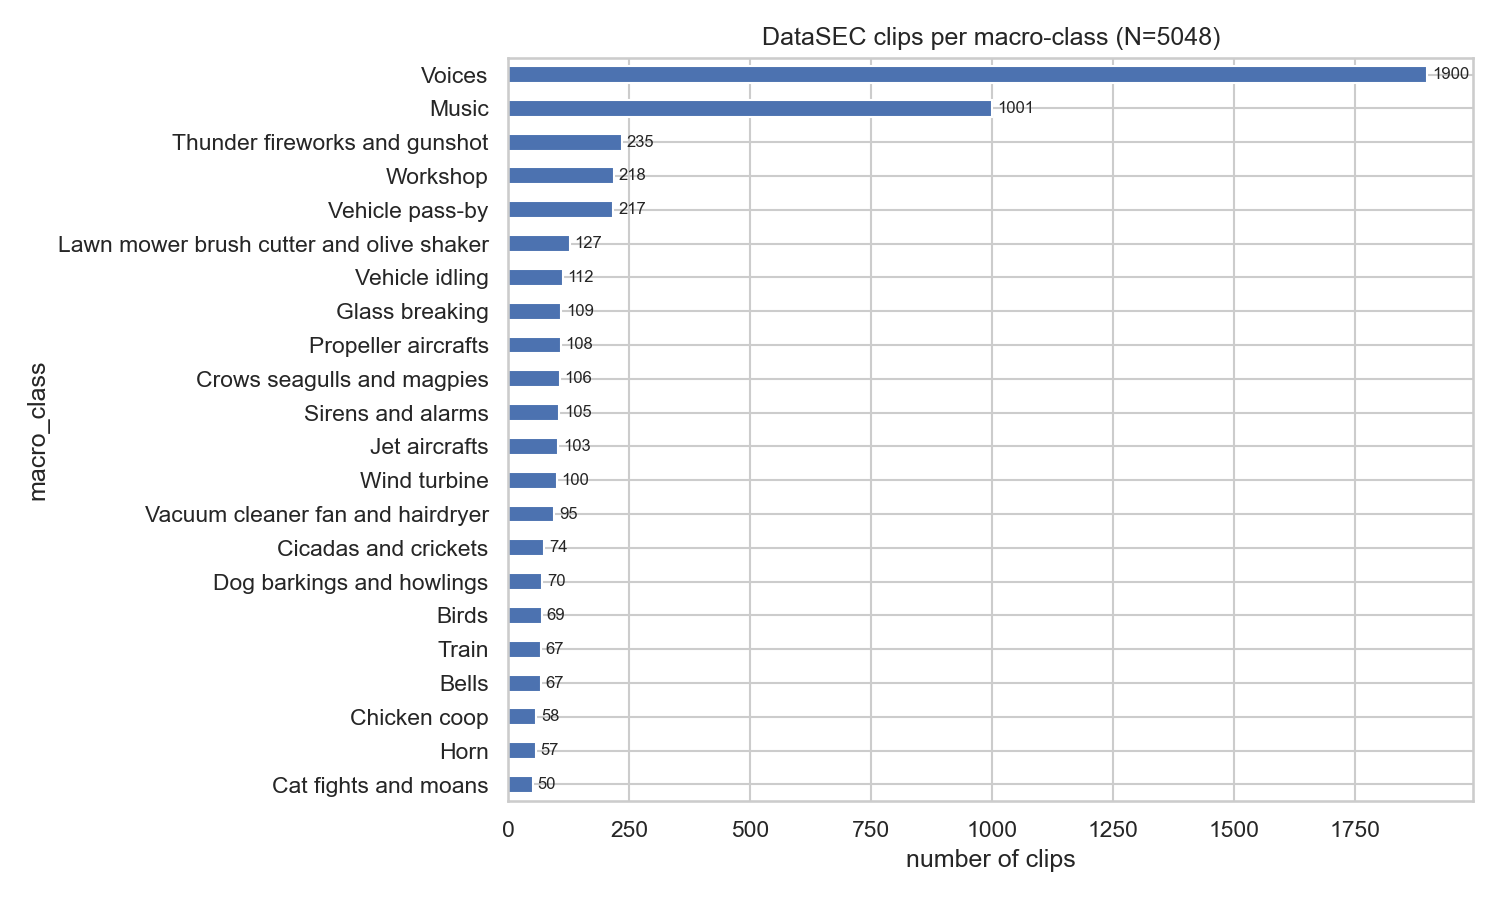

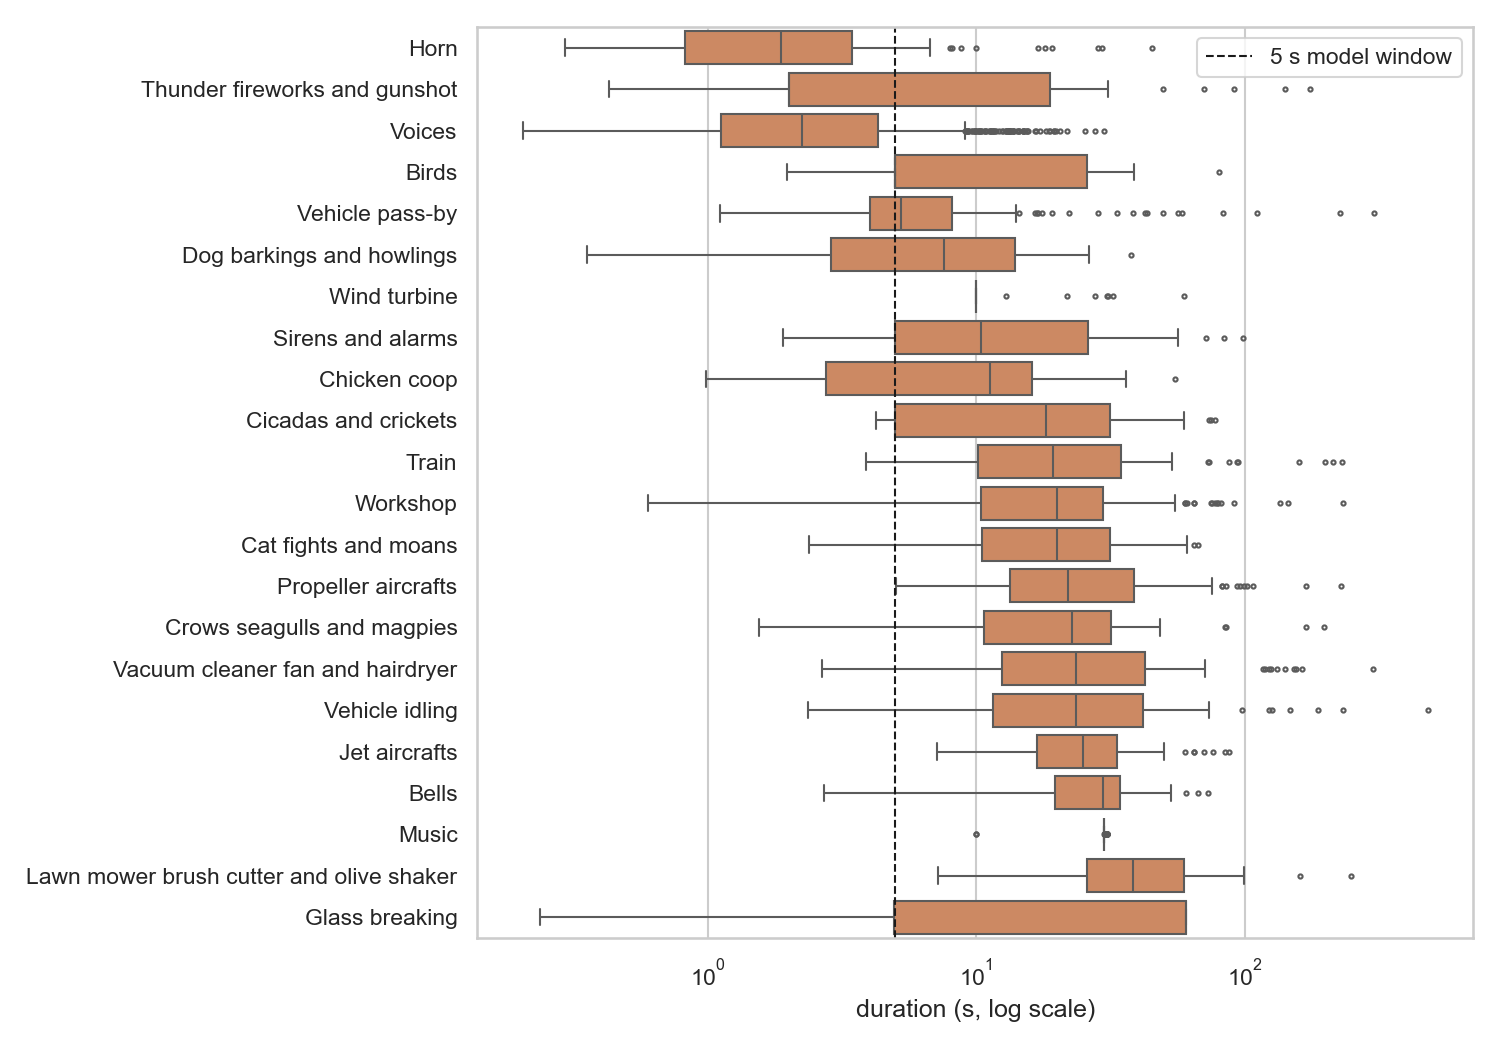

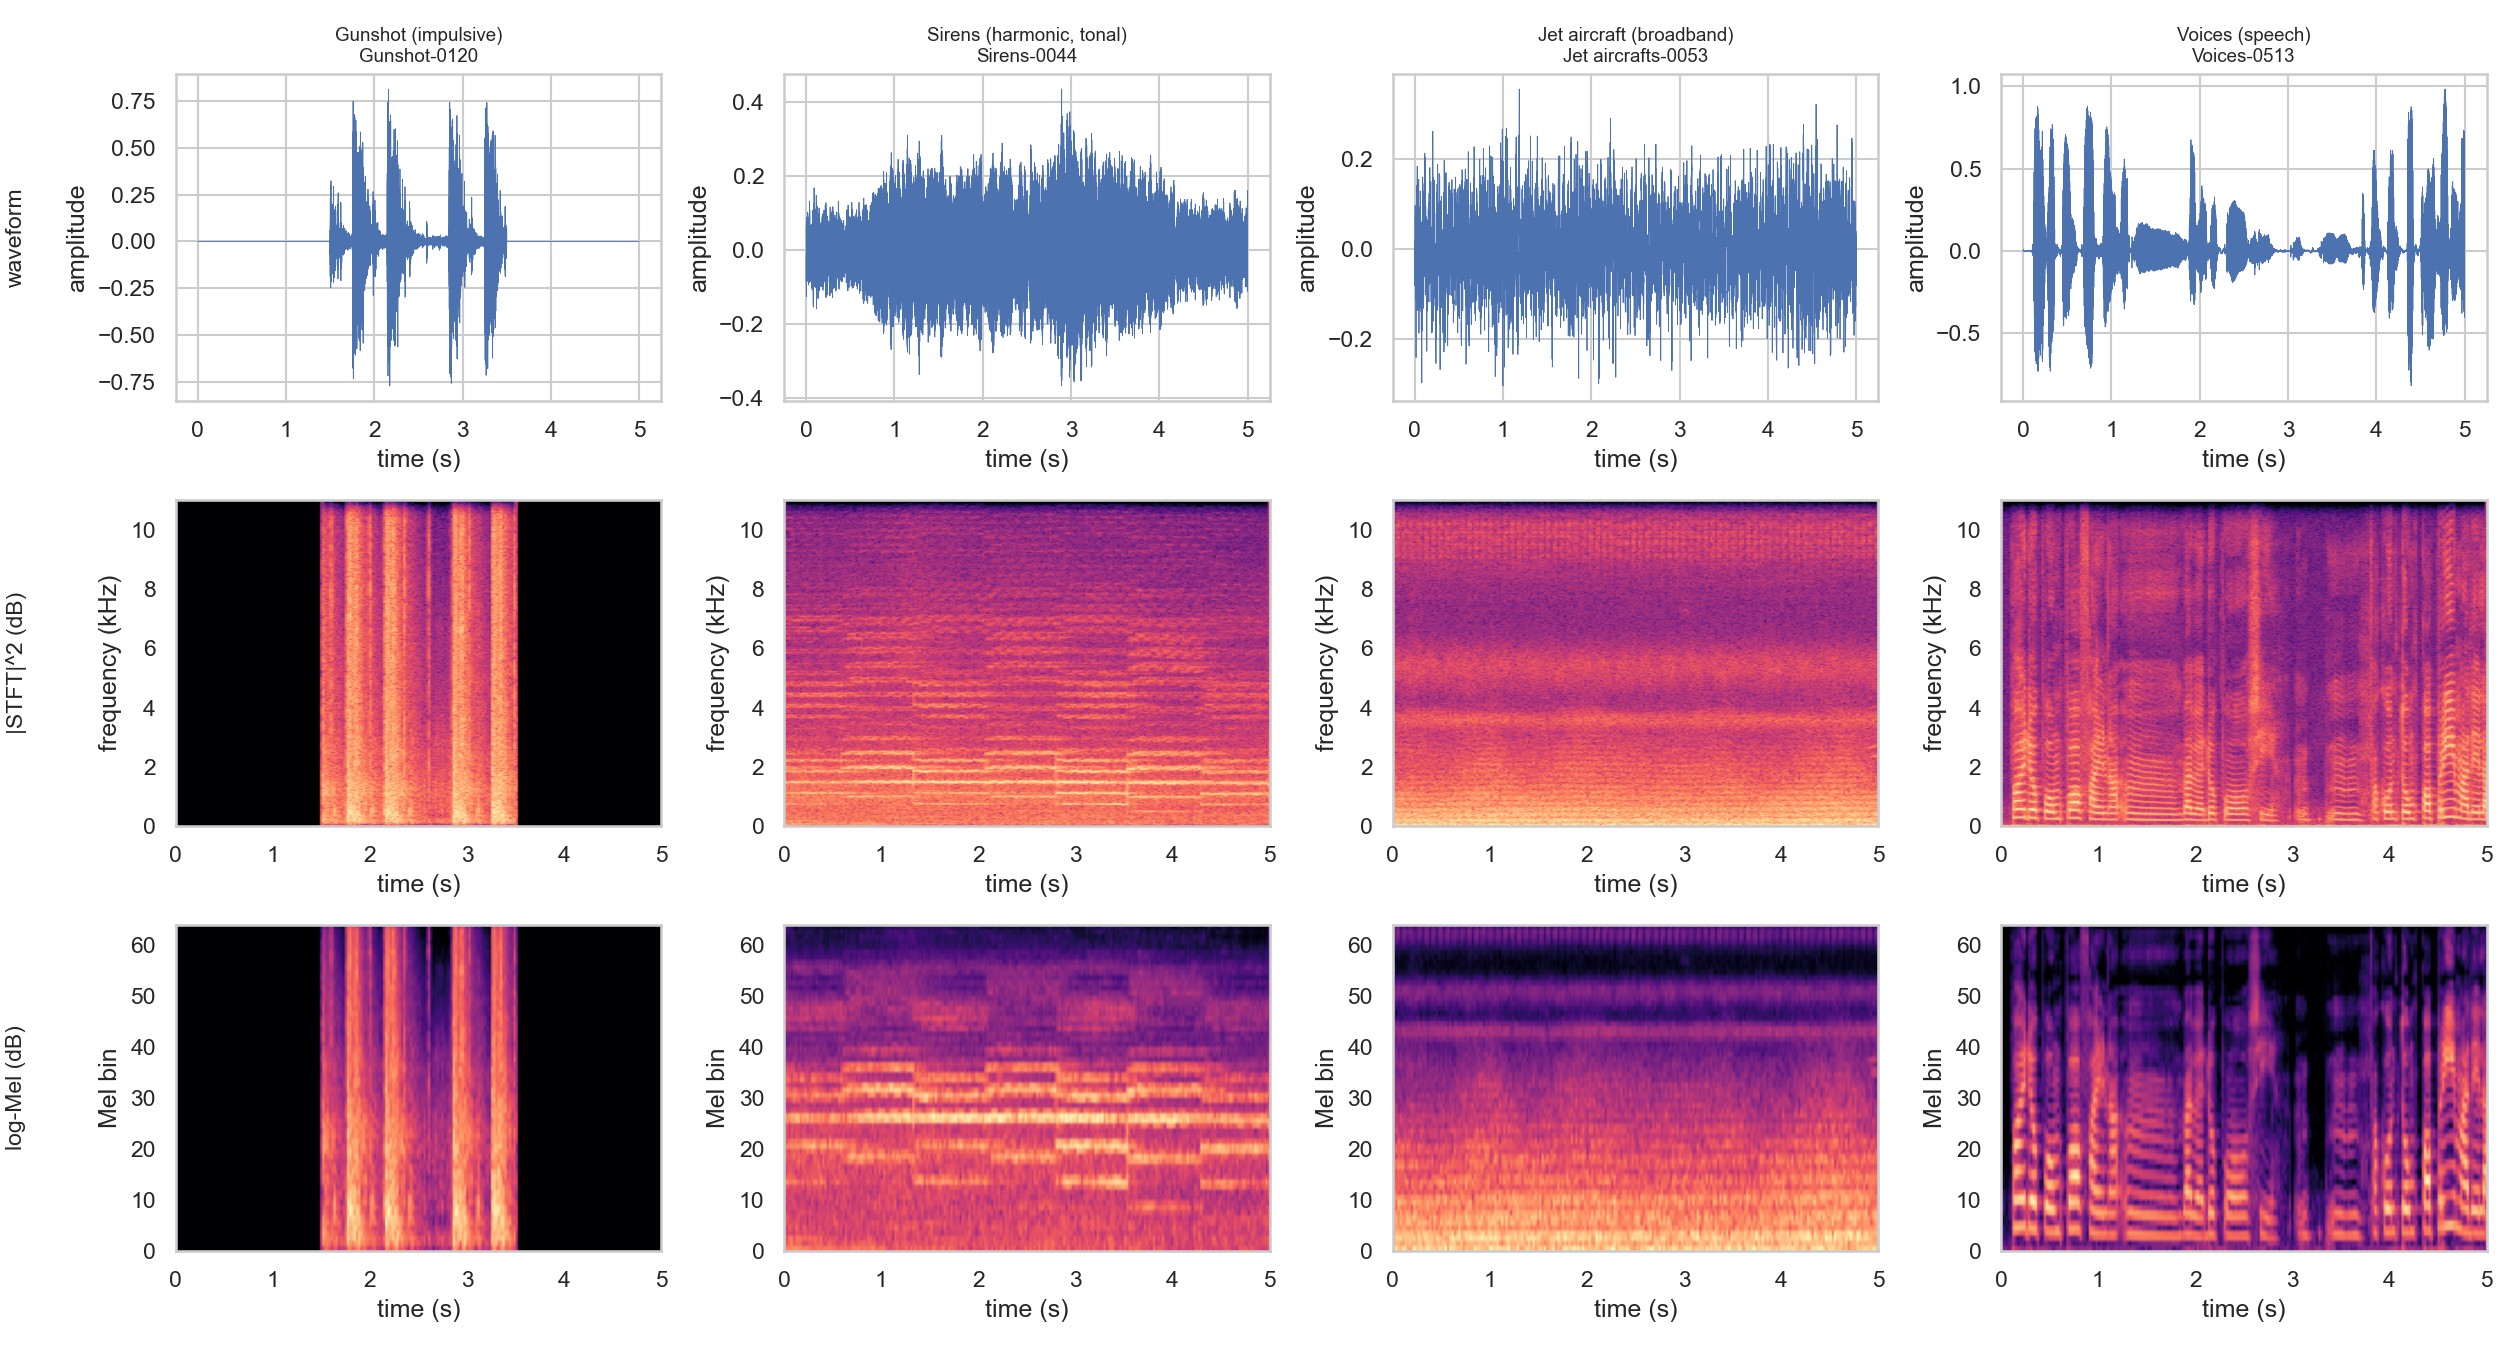

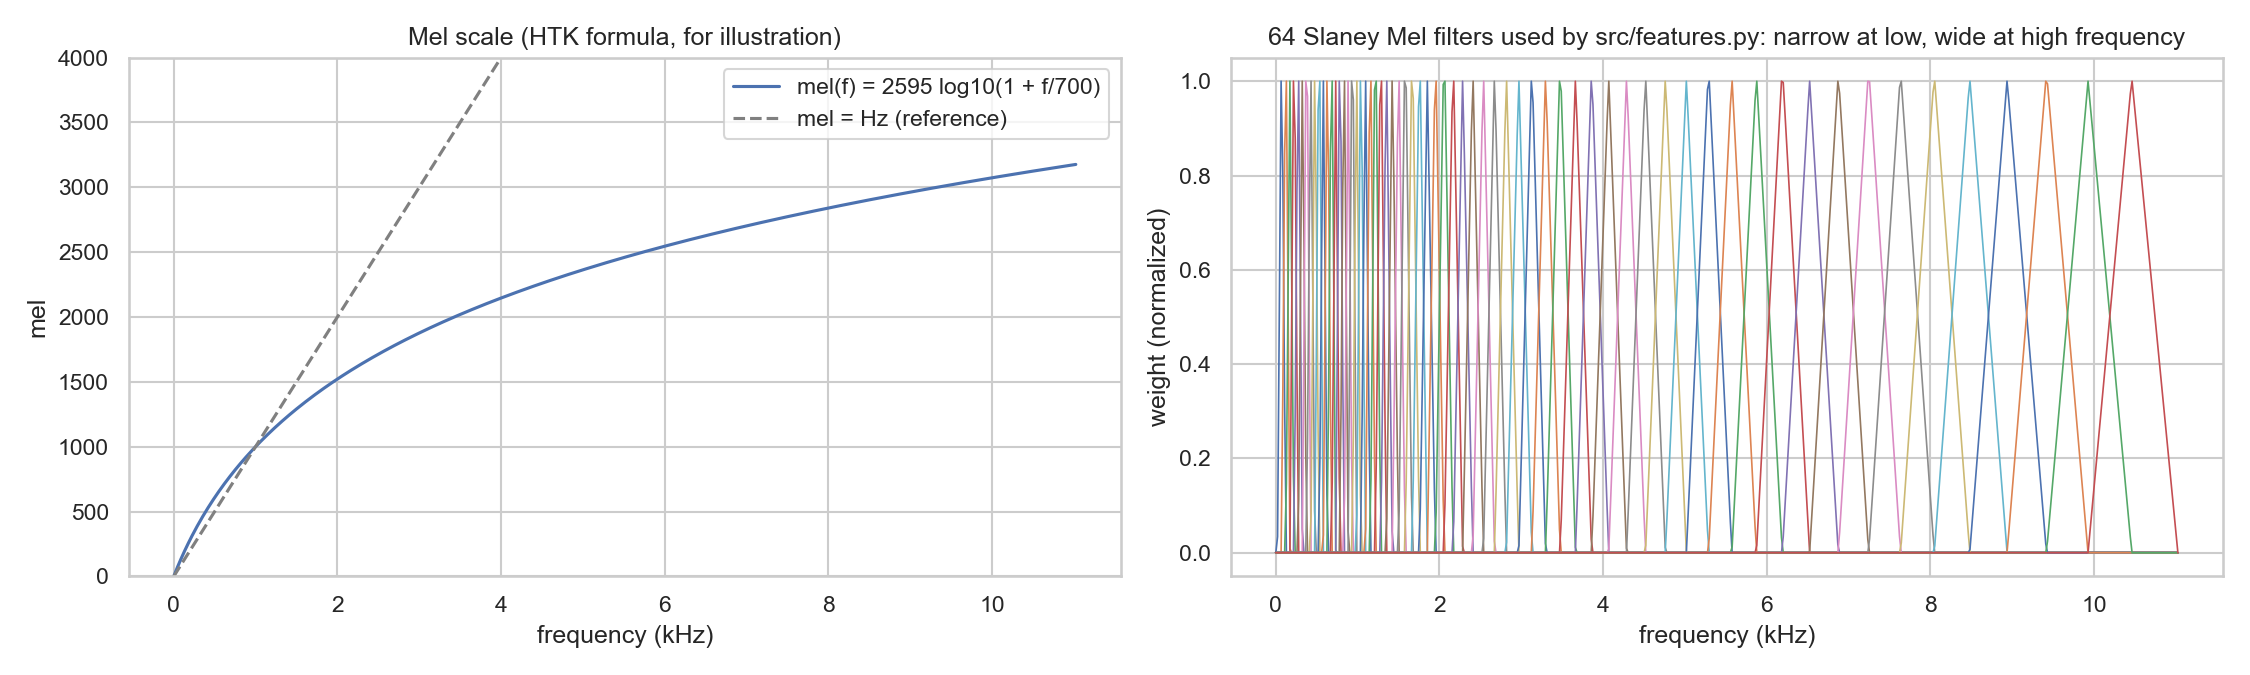

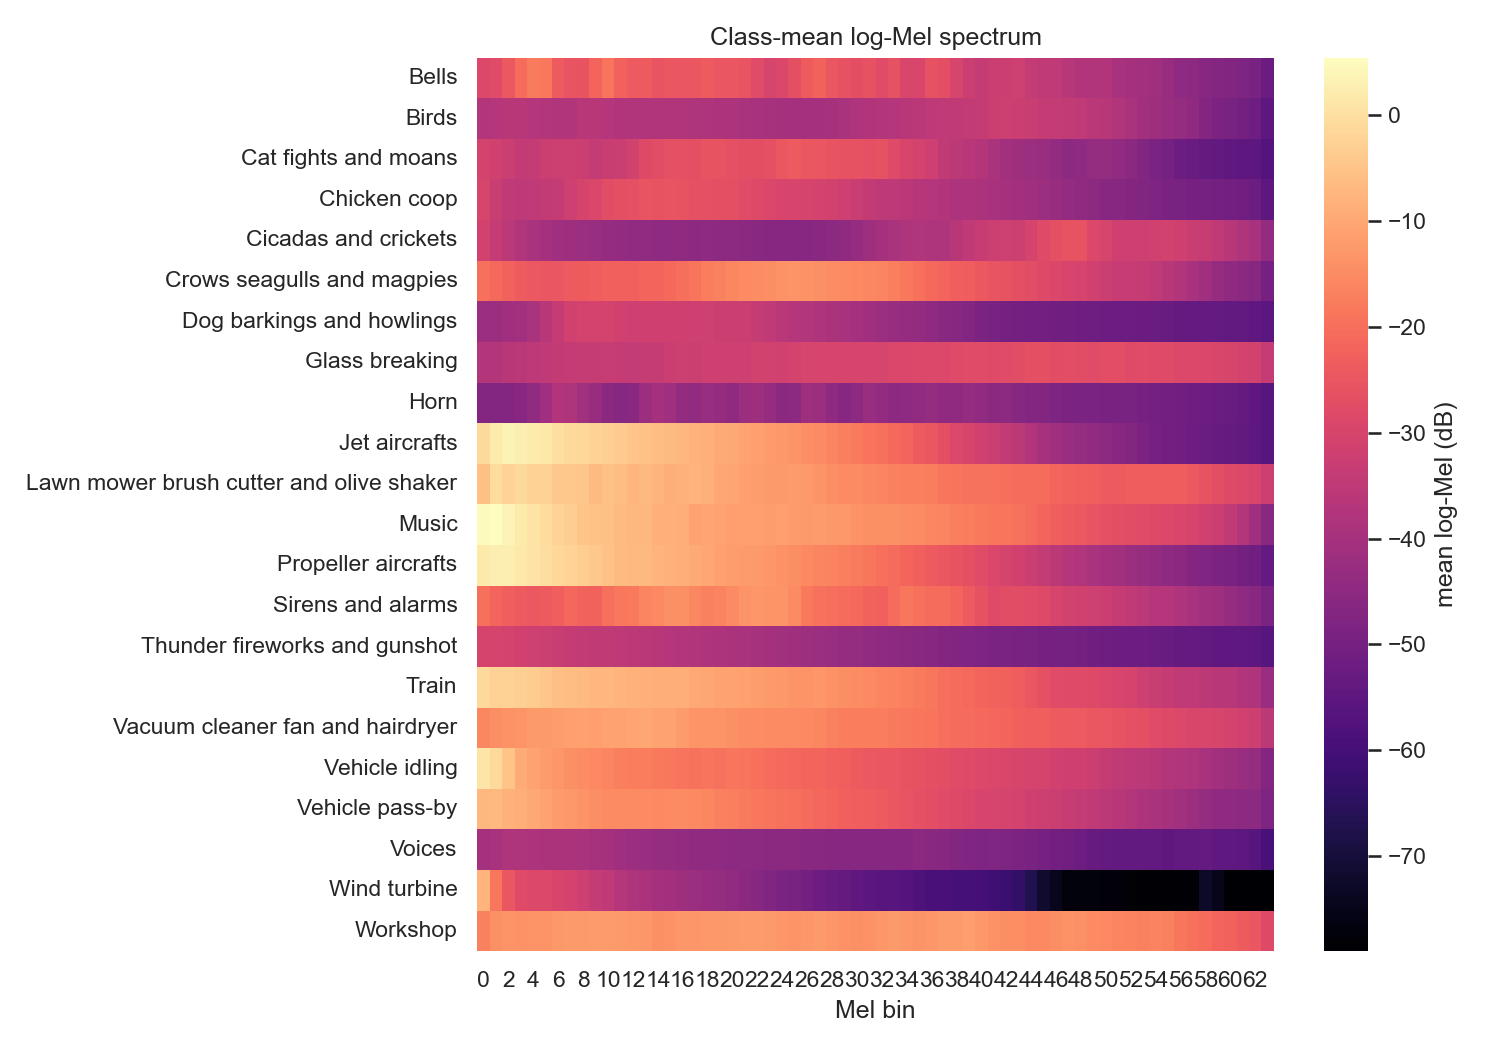

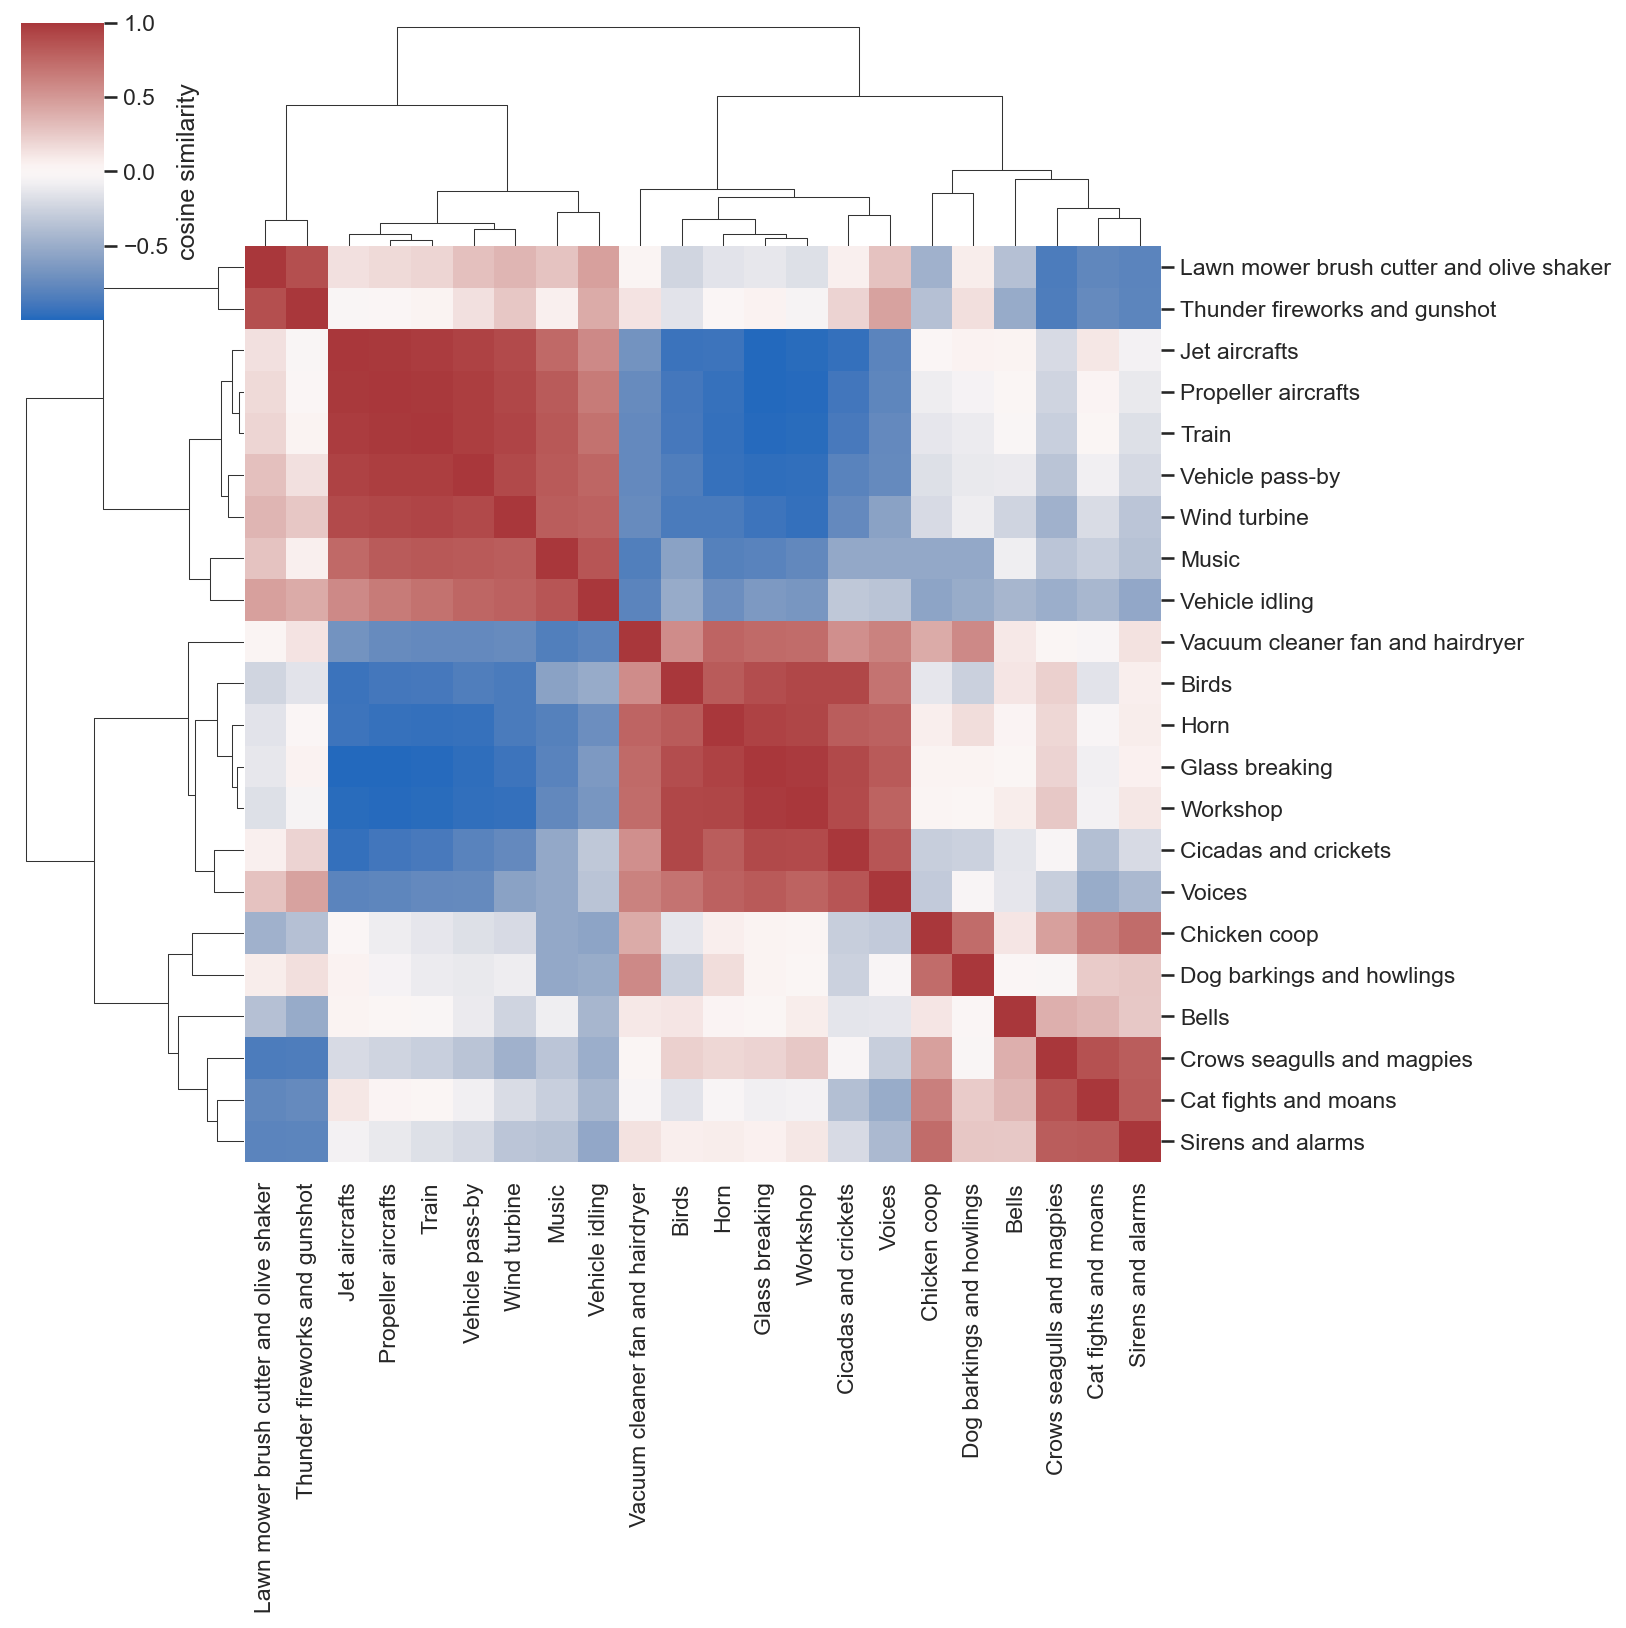

In [6]:
from src.utils import RESULTS

display(pd.read_csv(RESULTS / "tables" / "eda_duration_stats.csv"))
display(pd.read_csv(RESULTS / "tables" / "eda_similar_pairs.csv"))
display(Image(filename=str(RESULTS / "figures" / "eda_class_counts.png")))
display(Image(filename=str(RESULTS / "figures" / "eda_duration_box.png")))
display(Image(filename=str(RESULTS / "figures" / "eda_representations.png")))
display(Image(filename=str(RESULTS / "figures" / "eda_mel_filterbank.png")))
display(Image(filename=str(RESULTS / "figures" / "eda_class_mean_spectra.png")))
display(Image(filename=str(RESULTS / "figures" / "eda_spectral_similarity.png")))

## 2. Data quality and curation artefacts

Source: `scripts/eda_quality.py`

Data-quality checks for Midterm part A: overlapping clips, source bandwidth, level and fixed-length segments.

These are properties of how DataSEC was curated, not of the sounds themselves, and a model can learn them as
shortcuts. Writes:
  results/tables/eda_overlap_pairs.csv    clip pairs that share audio (identical file, one is a prefix of the
                                          other, or the same first seconds) and the split partition of each clip
  results/tables/eda_signal_quality.csv   per class: level, peak normalisation, high-frequency energy,
                                          source bandwidth and the most common clip length
  results/figures/eda_signal_quality.png
Needs data/index.csv (scripts/build_index.py), the extracted raw audio and splits/*.csv.

In [7]:
import argparse
import hashlib
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from scipy import signal
from tqdm import tqdm
from src.utils import RESULTS, load_config, resolve

In [8]:
CLIFF_EDGES_HZ = [4000, 5512.5, 8000, 11025, 16000, 19000]  # standard band edges of resampled / encoded audio
CLIFF_DB = 25.0      # PSD drop across an edge that marks a band-limited source
PEAK_NORM_DB = -0.1  # peak at or above this = clip was peak-normalised to full scale

In [9]:
def analyse(path: str) -> dict:
    """Level, high-frequency energy and source bandwidth of one clip (native 44.1 kHz)."""
    data, sr = sf.read(path, dtype="int16", always_2d=True)
    data = data[:, 0]
    x = data.astype(np.float32) / 32768.0
    f, psd = signal.welch(x, fs=sr, nperseg=min(4096, len(x)))
    tot = psd.sum() + 1e-30
    psd_db = 10 * np.log10(psd + 1e-20)
    bandwidth = sr / 2
    for fc in CLIFF_EDGES_HZ:
        below = np.median(psd_db[(f >= 0.80 * fc) & (f < 0.97 * fc)])
        above = np.median(psd_db[(f > 1.03 * fc) & (f <= min(1.2 * fc, 0.497 * sr))])
        if below - above > CLIFF_DB:
            bandwidth = fc
            break
    return {"peak_dbfs": float(20 * np.log10(max(np.abs(x).max(), 1e-10))),
            "rms_dbfs": float(10 * np.log10(max(np.mean(x.astype(np.float64) ** 2), 1e-20))),
            "energy_above_8k": float(psd[f >= 8000].sum() / tot),
            "energy_above_11k": float(psd[f >= 11025].sum() / tot),
            "source_bandwidth_hz": float(bandwidth),
            "md5_first_second": hashlib.md5(data[:sr].tobytes()).hexdigest()}

In [10]:
def overlap_pairs(df: pd.DataFrame, raw: Path) -> pd.DataFrame:
    """Pairs of clips that share audio: identical files (md5) or the same first second (verified sample by sample)."""
    rows = []
    for _, g in df[df.duplicated("md5", keep=False)].groupby("md5"):
        ids = g.sort_values("sample_id")
        for b in ids.iloc[1:].itertuples():
            rows.append((ids.iloc[0].sample_id, b.sample_id, "identical file", b.duration))
    same_start = df[(df.duration >= 1) & ~df.duplicated("md5", keep=False)
                    & df.duplicated("md5_first_second", keep=False)]
    for _, g in same_start.groupby("md5_first_second"):
        g = g.sort_values("duration")
        a = sf.read(raw / g.iloc[0].path, dtype="int16", always_2d=True)[0][:, 0]
        for b_row in g.iloc[1:].itertuples():
            b = sf.read(raw / b_row.path, dtype="int16", always_2d=True)[0][:, 0]
            m = min(len(a), len(b))
            differ = np.flatnonzero(a[:m] != b[:m])
            shared = (differ[0] if len(differ) else m) / g.iloc[0].sr
            relation = "prefix of the longer clip" if not len(differ) and m == len(a) else "same first seconds"
            rows.append((g.iloc[0].sample_id, b_row.sample_id, relation, shared))
    return pd.DataFrame(rows, columns=["sample_a", "sample_b", "relation", "shared_s"])

In [11]:
def main_eda_quality() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--workers", type=int, default=8)
    args = ap.parse_args()
    cfg = load_config()
    fig_dir, tab_dir = RESULTS / "figures", RESULTS / "tables"
    fig_dir.mkdir(parents=True, exist_ok=True); tab_dir.mkdir(parents=True, exist_ok=True)
    raw = resolve(cfg["dataset"]["raw_dir"]) / "DATASEC"
    df = pd.read_csv(resolve(cfg["dataset"]["index_csv"]))

    with ProcessPoolExecutor(args.workers) as ex:
        stats = list(tqdm(ex.map(analyse, [str(raw / p) for p in df.path], chunksize=16), total=len(df), desc="clips"))
    df = pd.concat([df, pd.DataFrame(stats)], axis=1)

    # 1. overlapping clips and where the split put them
    split_of = pd.concat([pd.read_csv(resolve(cfg["dataset"]["splits_dir"]) / f"{s}.csv").assign(split=s)
                          for s in ("train", "val", "test")]).set_index("sample_id").split
    pairs = overlap_pairs(df, raw)
    pairs["macro_class"] = pairs.sample_a.map(df.set_index("sample_id").macro_class)
    pairs["split_a"], pairs["split_b"] = pairs.sample_a.map(split_of), pairs.sample_b.map(split_of)
    pairs["crosses_split"] = pairs.split_a != pairs.split_b
    pairs.round(2).to_csv(tab_dir / "eda_overlap_pairs.csv", index=False)
    print(f"overlapping pairs: {len(pairs)} ({pairs.relation.value_counts().to_dict()}) | "
          f"crossing partitions: {int(pairs.crosses_split.sum())}")
    if pairs.crosses_split.any():
        print(pairs[pairs.crosses_split].to_string(index=False))

    # 2. per-class curation artefacts
    bucket = pd.cut(df.source_bandwidth_hz, [0, 8000, 11025, 19000, np.inf],
                    labels=["cliff <= 8 kHz", "cliff at 11.025 kHz", "cliff at 16-19 kHz", "full band"])
    common_len = df.duration.round(1)
    q = df.assign(peak_normalised=df.peak_dbfs >= PEAK_NORM_DB, over_1pct_above_8k=df.energy_above_8k > 0.01,
                  over_1pct_above_11k=df.energy_above_11k > 0.01, common_len=common_len)
    tab = q.groupby("macro_class").agg(
        n=("sample_id", "size"), rms_dbfs_median=("rms_dbfs", "median"), peak_dbfs_median=("peak_dbfs", "median"),
        pct_peak_normalised=("peak_normalised", "mean"),
        energy_above_8k_pct_median=("energy_above_8k", "median"),
        pct_over_1pct_energy_above_8k=("over_1pct_above_8k", "mean"),
        pct_over_1pct_energy_above_11k=("over_1pct_above_11k", "mean"),
        most_common_length_s=("common_len", lambda s: s.mode().iloc[0]),
        pct_most_common_length=("common_len", lambda s: (s == s.mode().iloc[0]).mean()))
    for c in ["pct_peak_normalised", "energy_above_8k_pct_median", "pct_over_1pct_energy_above_8k",
              "pct_over_1pct_energy_above_11k", "pct_most_common_length"]:
        tab[c] *= 100
    bw = pd.crosstab(df.macro_class, bucket, normalize="index") * 100
    tab = tab.join(bw.add_prefix("pct_")).sort_values("n", ascending=False)
    tab.round(2).to_csv(tab_dir / "eda_signal_quality.csv")
    print(tab.round(1).to_string())
    print(f"all clips: >1% energy above 8 kHz {100 * q.over_1pct_above_8k.mean():.1f}% | "
          f"above 11.025 kHz {100 * q.over_1pct_above_11k.mean():.1f}%")

    order = list(tab.index[::-1])
    y = np.arange(len(order))
    plt.style.use("seaborn-v0_8-whitegrid")
    fig, axes = plt.subplots(1, 3, figsize=(17, 7), sharey=True)
    axes[0].boxplot([df.loc[df.macro_class == c, "rms_dbfs"] for c in order], positions=y, vert=False,
                    showfliers=False, widths=0.6)
    axes[0].set_yticks(y, order)
    axes[0].set_xlabel("RMS level (dBFS)"); axes[0].set_title("Clip level")
    axes[1].barh(y, tab.loc[order, "pct_peak_normalised"], color="#4C72B0")
    axes[1].set_xlabel("% clips with peak at 0 dBFS"); axes[1].set_title("Peak-normalised clips")
    left = np.zeros(len(order))
    for col, colour in zip(bw.columns, ["#1f3b73", "#4C72B0", "#a6c1e3", "#d9d9d9"]):
        v = bw.reindex(order)[col].fillna(0).values
        axes[2].barh(y, v, left=left, color=colour, label=col); left += v
    axes[2].set_xlabel("% clips"); axes[2].set_title("Estimated source bandwidth (PSD cliff > 25 dB)")
    axes[2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2, fontsize=8)
    plt.tight_layout(); plt.savefig(fig_dir / "eda_signal_quality.png", dpi=150); plt.close()
    print(f"-> {tab_dir}/eda_overlap_pairs.csv, eda_signal_quality.csv, {fig_dir}/eda_signal_quality.png")

In [12]:
# the worker must be importable for multiprocessing on Windows / macOS (spawn)
from scripts.eda_quality import analyse  # noqa: F811

# same as: python scripts/eda_quality.py --workers 8
sys.argv = ["scripts/eda_quality.py", "--workers", "8"]
main_eda_quality()

clips:   0%|          | 0/5048 [00:00<?, ?it/s]

clips:   0%|          | 1/5048 [00:04<6:11:25,  4.42s/it]

clips:   4%|▎         | 177/5048 [00:04<01:30, 53.94it/s]

clips:   5%|▌         | 257/5048 [00:05<01:16, 62.99it/s]

clips:   6%|▌         | 292/5048 [00:06<01:28, 53.89it/s]

...

clips:  98%|█████████▊| 4938/5048 [00:49<00:00, 115.23it/s]

clips:  99%|█████████▊| 4977/5048 [00:49<00:00, 128.43it/s]

clips: 100%|██████████| 5048/5048 [00:49<00:00, 102.20it/s]

overlapping pairs: 24 ({'identical file': 16, 'prefix of the longer clip': 5, 'same first seconds': 3}) | crossing partitions: 2
         sample_a          sample_b                  relation  shared_s                              macro_class split_a split_b  crosses_split
       Crows-0017        Crows-0016 prefix of the longer clip 33.913016               Crows seagulls and magpies    test   train           True
Olive shaker-0014 Olive shaker-0015        same first seconds  4.802993 Lawn mower brush cutter and olive shaker   train    test           True
                                             n  rms_dbfs_median  peak_dbfs_median  pct_peak_normalised  energy_above_8k_pct_median  pct_over_1pct_energy_above_8k  pct_over_1pct_energy_above_11k  most_common_length_s  pct_most_common_length  pct_cliff <= 8 kHz  pct_cliff at 11.025 kHz  pct_cliff at 16-19 kHz  pct_full band
macro_class                                                                                                        

-> C:\ATI\DataSEC-Sound-Classification-main\results\tables/eda_overlap_pairs.csv, eda_signal_quality.csv, C:\ATI\DataSEC-Sound-Classification-main\results\figures/eda_signal_quality.png


,sample_a,sample_b,relation,shared_s,macro_class,split_a,split_b,crosses_split
0,Music-0756,Music-0762,identical file,30.00,Music,train,train,False
1,Glass breaking-0097,Glass breaking-0098,identical file,8.68,Glass breaking,train,train,False
2,Music-0399,Music-0400,identical file,30.00,Music,val,val,False
3,Crows-0035,Crows-0050,identical file,17.83,Crows seagulls and magpies,train,train,False
4,Music-0642,Music-0663,identical file,30.01,Music,val,val,False
5,Music-0641,Music-0662,identical file,30.01,Music,val,val,False
6,Music-0477,Music-0479,identical file,30.00,Music,train,train,False
7,Music-0644,Music-0665,identical file,30.01,Music,train,train,False
8,Music-0640,Music-0661,identical file,30.01,Music,train,train,False
9,Music-0634,Music-0694,identical file,30.00,Music,test,test,False


,macro_class,n,rms_dbfs_median,peak_dbfs_median,pct_peak_normalised,energy_above_8k_pct_median,pct_over_1pct_energy_above_8k,pct_over_1pct_energy_above_11k,most_common_length_s,pct_most_common_length,pct_cliff <= 8 kHz,pct_cliff at 11.025 kHz,pct_cliff at 16-19 kHz,pct_full band
0,Voices,1900,-19.94,-0.00,65.79,0.15,12.32,0.00,0.5,4.63,0.16,88.32,0.00,11.53
1,Music,1001,-17.05,-1.01,33.27,0.25,19.38,1.80,30.0,96.40,0.00,71.53,19.68,8.79
2,Thunder fireworks and gunshot,235,-21.10,-2.35,13.19,0.95,48.94,22.55,2.0,51.49,0.43,1.28,49.36,48.94
3,Workshop,218,-23.79,-3.86,12.84,6.03,81.65,61.01,29.8,6.88,0.46,1.83,7.34,90.37
4,Vehicle pass-by,217,-21.02,-3.38,8.29,0.15,14.75,4.61,5.0,6.91,0.92,10.60,43.78,44.70
5,Lawn mower brush cutter and olive shaker,127,-23.26,-3.73,14.96,1.81,68.50,41.73,59.3,22.05,0.00,4.72,22.05,73.23
6,Vehicle idling,112,-23.90,-6.24,8.04,0.12,22.32,13.39,61.4,5.36,0.00,1.79,6.25,91.96
7,Glass breaking,109,-18.46,0.00,76.15,24.16,99.08,98.17,60.5,55.96,0.00,0.92,71.56,27.52
8,Propeller aircrafts,108,-22.72,-5.68,10.19,0.00,1.85,0.00,10.0,2.78,0.00,2.78,8.33,88.89
9,Crows seagulls and magpies,106,-25.34,-6.46,0.94,0.06,7.55,0.94,28.3,9.43,1.89,0.94,19.81,77.36


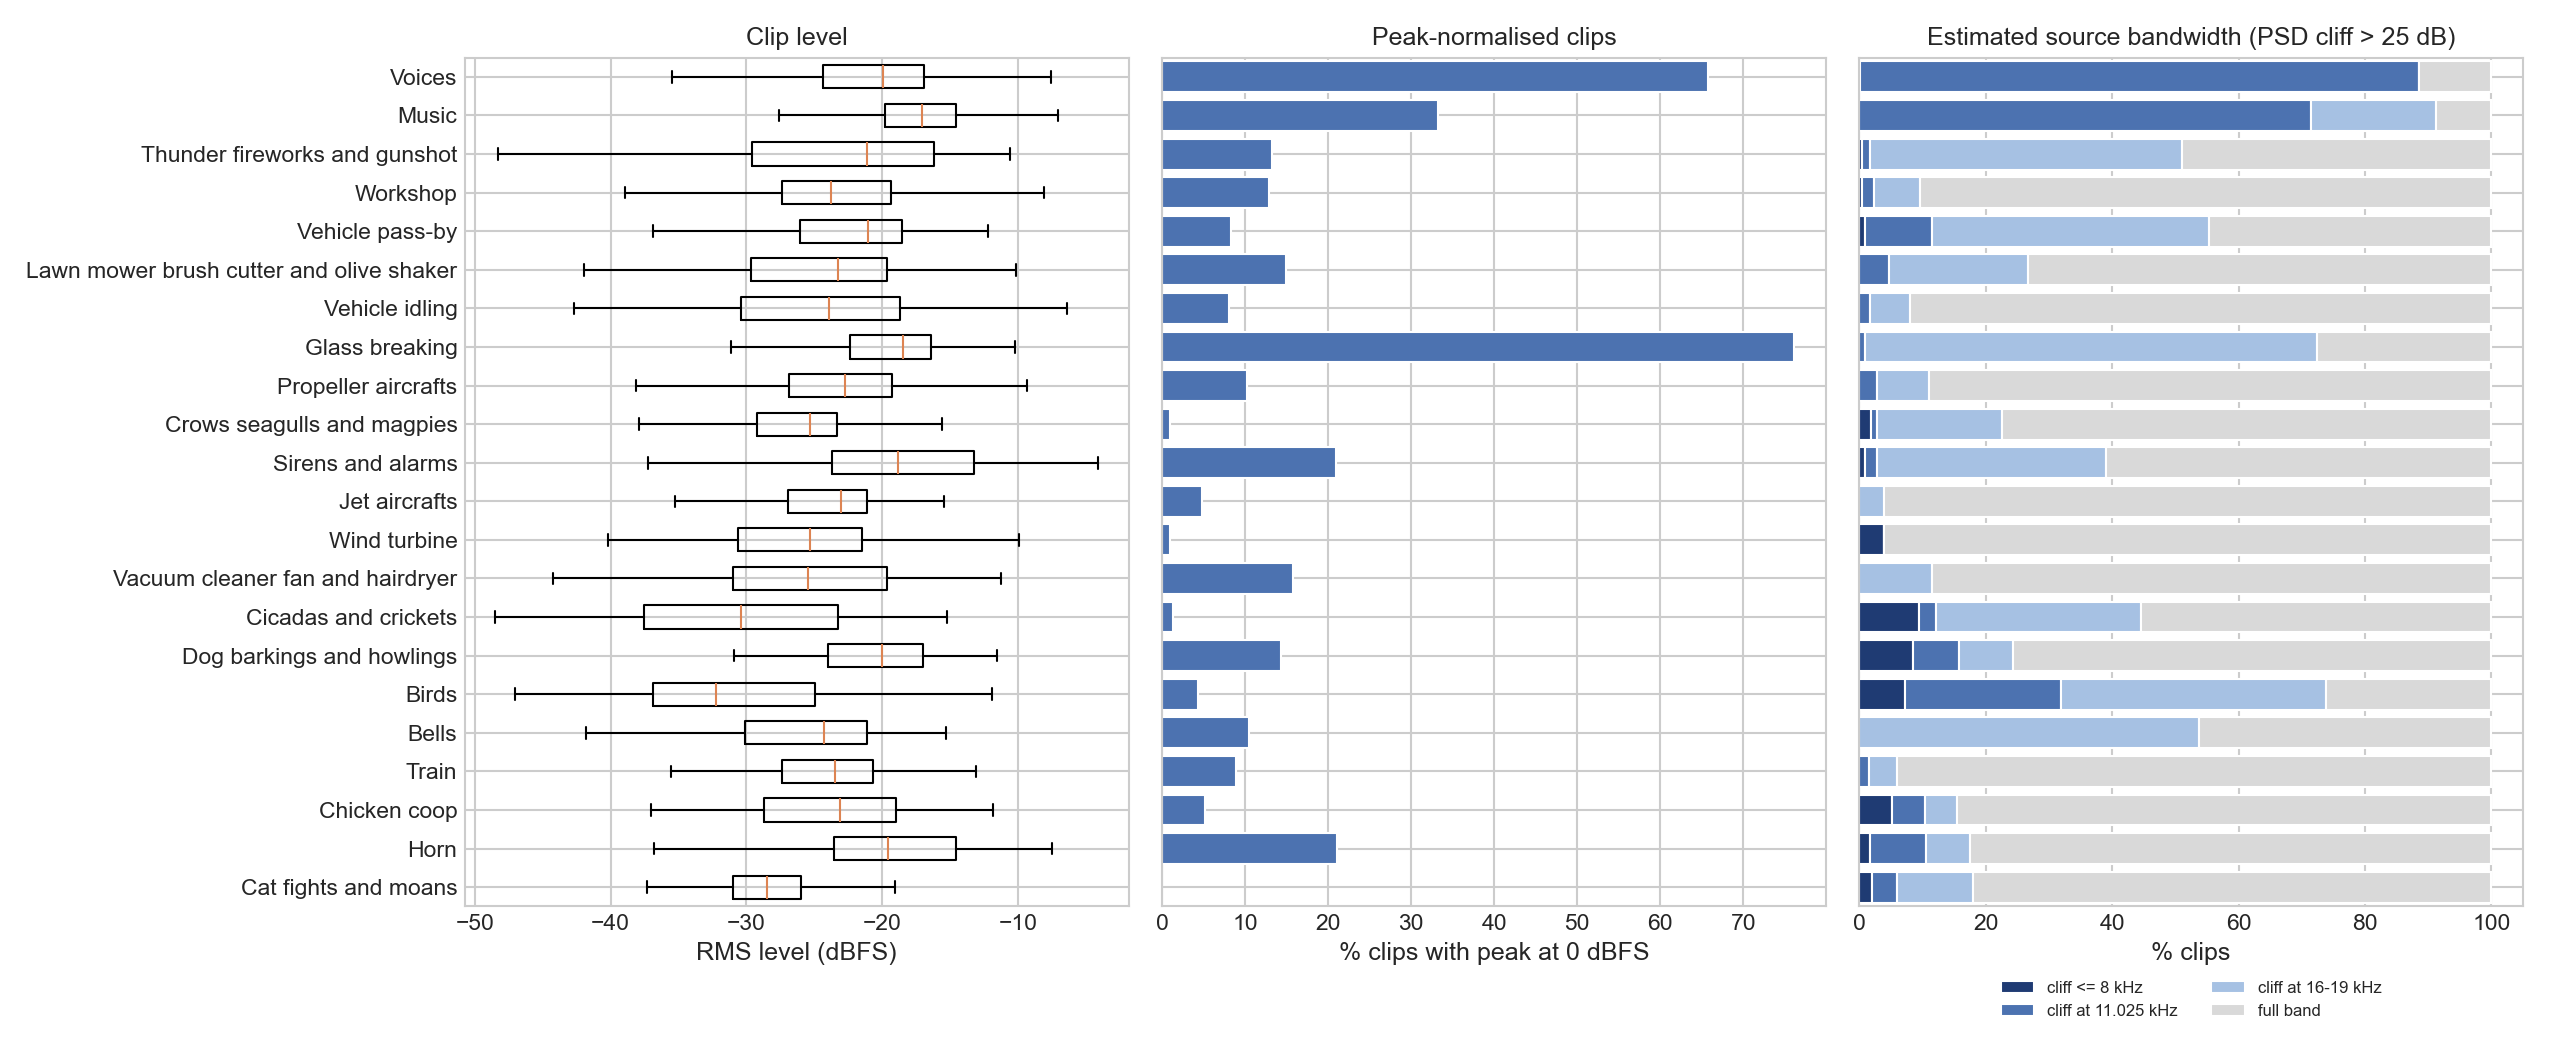

In [13]:
from src.utils import RESULTS

display(pd.read_csv(RESULTS / "tables" / "eda_overlap_pairs.csv"))
display(pd.read_csv(RESULTS / "tables" / "eda_signal_quality.csv"))
display(Image(filename=str(RESULTS / "figures" / "eda_signal_quality.png")))